<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/statistical_field_theory/sft_ch04_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Statistical Field Theory* — `sft_ch04_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SFT Ch 4 Figures — Colab Notebook
**Statistical Field Theory · Chapter 4: Continuous Symmetries**

PSE Lab · SeoulTech · Tong (Cambridge)

Figures saved to `figures/ch04/`. Run each cell independently.

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | Goldstone bosons: Mexican hat, dispersion, counting | §4.1 |
| fig02 | Mermin-Wagner: IR divergence, $\langle m\rangle(d)$, QLRO | §4.2 |
| fig03 | Sigma model: asymptotic freedom, mass gap | §4.3 |
| fig04 | KT transition: vortex $F_v$, phase diagram, $\eta(T)$ | §4.4 |
| fig05 | KT RG flow $(K,y)$ + essential singularity $\xi$ | §4.4.3 |

---
## fig01 · Goldstone Bosons (§4.1)

**Left**: $O(2)$ Mexican hat potential — flat Goldstone direction. **Centre**: Dispersion — massless Goldstone $\omega=v_sk$ vs massive radial mode. **Right**: Goldstone count $N-1$ for $O(N)\to O(N-1)$.

  saved -> figures/ch04/fig01_goldstone.png


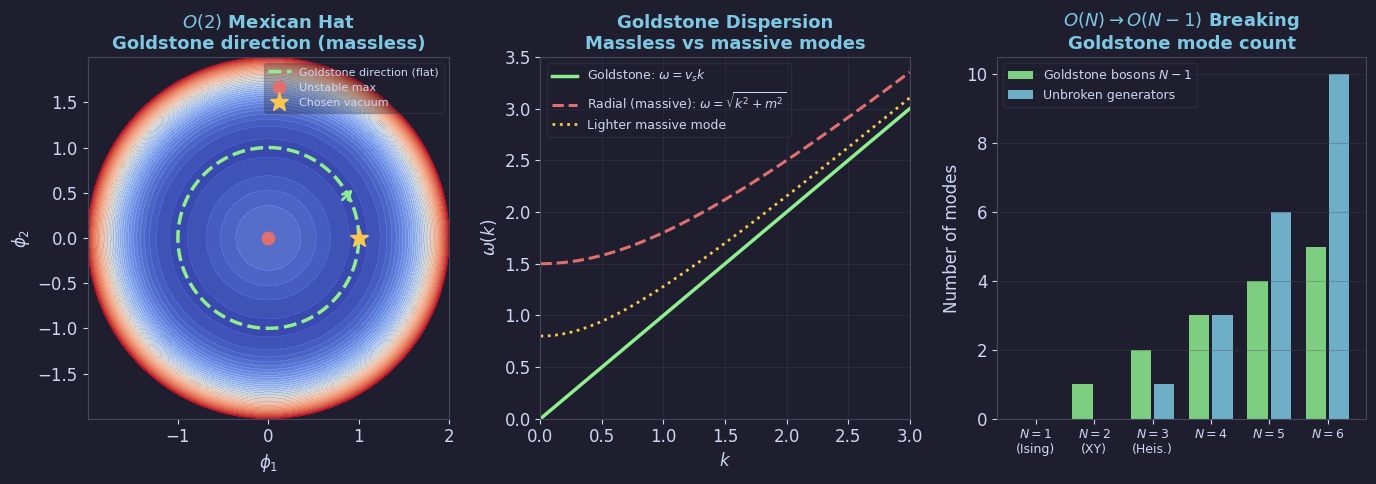

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01: Goldstone bosons — Mexican hat, dispersion, counting (Ch 4.1) ──
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Panel 1: Mexican hat O(2)
ax = axes[0]
phi = np.linspace(0, 2*np.pi, 300)
r_v = np.linspace(0, 2, 100)
R, PHI = np.meshgrid(r_v, phi)
X = R*np.cos(PHI); Y = R*np.sin(PHI)
V = -0.5*R**2 + 0.25*R**4
ax.contourf(X, Y, V, levels=40, cmap='coolwarm', alpha=0.85)
r0 = 1.0
ax.plot(r0*np.cos(phi), r0*np.sin(phi), color=GREEN, lw=2.5, ls='--',
        label='Goldstone direction (flat)')
ax.plot([0],[0],'o',color=RED,ms=9,label='Unstable max')
ax.plot([r0],[0],'*',color=YELLOW,ms=14,label='Chosen vacuum')
ax.annotate('', xy=(r0*np.cos(0.5)+0.08, r0*np.sin(0.5)+0.08),
            xytext=(r0*np.cos(0.5)-0.08, r0*np.sin(0.5)-0.08),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.0, mutation_scale=14))
ax.set_aspect('equal')
ax.set_xlabel(r'$\phi_1$'); ax.set_ylabel(r'$\phi_2$')
ax.set_title(r'$O(2)$ Mexican Hat'+'\nGoldstone direction (massless)', color=BLUE)
ax.legend(fontsize=8, labelcolor=FG)

# Panel 2: dispersion relations
ax2 = axes[1]
k = np.linspace(0, 3, 300)
ax2.plot(k, k, color=GREEN, lw=2.5, label=r'Goldstone: $\omega=v_sk$')
ax2.plot(k, np.sqrt(k**2+1.5**2), color=RED, lw=2.2, ls='--',
         label=r'Radial (massive): $\omega=\sqrt{k^2+m^2}$')
ax2.plot(k, np.sqrt(k**2+0.8**2), color=YELLOW, lw=2.0, ls=':',
         label=r'Lighter massive mode')
ax2.set_xlabel(r'$k$'); ax2.set_ylabel(r'$\omega(k)$')
ax2.set_title("Goldstone Dispersion\nMassless vs massive modes", color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0,3); ax2.set_ylim(0,3.5)

# Panel 3: Goldstone counting bar chart
ax3 = axes[2]
N_vals = np.arange(1, 7)
n_ON  = N_vals*(N_vals-1)//2
n_ON1 = (N_vals-1)*(N_vals-2)//2
n_broken = n_ON - n_ON1   # = N-1
ax3.bar(N_vals-0.2, n_broken, 0.35, color=GREEN, alpha=0.85,
        label='Goldstone bosons $N-1$')
ax3.bar(N_vals+0.2, n_ON1, 0.35, color=BLUE, alpha=0.85,
        label='Unbroken generators')
labels = ['$N=1$\n(Ising)','$N=2$\n(XY)','$N=3$\n(Heis.)','$N=4$','$N=5$','$N=6$']
ax3.set_xticks(N_vals); ax3.set_xticklabels(labels, fontsize=9)
ax3.set_ylabel('Number of modes')
ax3.set_title(r'$O(N)\to O(N-1)$ Breaking'+'\nGoldstone mode count', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True, axis='y')

plt.tight_layout(pad=1.2)
save('fig01_goldstone.png', fig)


---
## fig02 · Mermin-Wagner Theorem (§4.2)

**Left**: Goldstone integrand $k^{d-3}$ — IR divergent for $d\leq2$. **Centre**: $\langle m\rangle(d)$ — SSB impossible for continuous symmetry in $d\leq2$. **Right**: Quasi-LRO $G(r)\sim r^{-\eta}$ in 2D XY.

/tmp/ipykernel_3410/4133163139.py:50: RuntimeWarning: invalid value encountered in sqrt
  m_order = np.where(d_arr > 2, (1-(2/d_arr)**2)**0.5, 0.0)


  saved -> figures/ch04/fig02_mermin_wagner.png


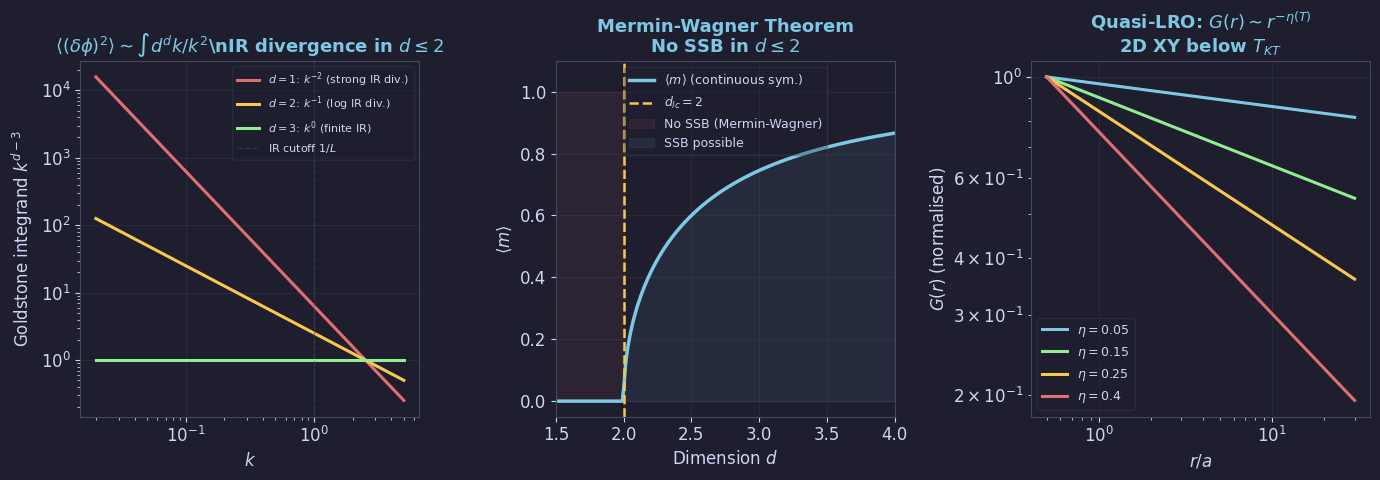

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02: Mermin-Wagner — IR divergence, LRO, QLRO (Ch 4.2) ─────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Panel 1: IR divergence of Goldstone integral
ax = axes[0]
k = np.linspace(0.02, 5, 500)
for d, col, lab in [(1,RED,r'$d=1$: $k^{-2}$ (strong IR div.)'),
                     (2,YELLOW,r'$d=2$: $k^{-1}$ (log IR div.)'),
                     (3,GREEN,r'$d=3$: $k^0$ (finite IR)')]:
    integrand = k**(d-1)/k**2
    ax.loglog(k, integrand/integrand[len(k)//2], color=col, lw=2.2, label=lab)
ax.axvline(1.0, color=EDGE, lw=1.0, ls='--', alpha=0.5, label='IR cutoff $1/L$')
ax.set_xlabel(r'$k$')
ax.set_ylabel(r'Goldstone integrand $k^{d-3}$')
ax.set_title(r'$\langle(\delta\phi)^2\rangle\sim\int d^dk/k^2$'+
             r'\nIR divergence in $d\leq2$', color=BLUE)
ax.legend(fontsize=8, labelcolor=FG); ax.grid(True)

# Panel 2: order parameter vs d
ax2 = axes[1]
d_arr = np.linspace(1.5, 4, 200)
m_order = np.where(d_arr > 2, (1-(2/d_arr)**2)**0.5, 0.0)
ax2.plot(d_arr, m_order, color=BLUE, lw=2.5,
         label=r'$\langle m\rangle$ (continuous sym.)')
ax2.axvline(2, color=YELLOW, lw=1.8, ls='--', label=r'$d_{lc}=2$')
ax2.fill_between(d_arr[d_arr<=2], 0, 1.0, color=RED, alpha=0.08,
                 label='No SSB (Mermin-Wagner)')
ax2.fill_between(d_arr[d_arr>2], 0, m_order[d_arr>2],
                 color=BLUE, alpha=0.08, label='SSB possible')
ax2.set_xlabel('Dimension $d$'); ax2.set_ylabel(r'$\langle m\rangle$')
ax2.set_title('Mermin-Wagner Theorem\n'+r'No SSB in $d\leq2$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(1.5,4); ax2.set_ylim(-0.05,1.1)

# Panel 3: G(r) with power-law decay (QLRO)
ax3 = axes[2]
r = np.linspace(0.5, 30, 400)
for eta_v, col, lab in [(0.05,BLUE,r'$\eta=0.05$'),
                         (0.15,GREEN,r'$\eta=0.15$'),
                         (0.25,YELLOW,r'$\eta=1/4$ ($T=T_{KT}$)'),
                         (0.40,RED,r'$\eta=0.40$')]:
    G = r**(-eta_v); G /= G[0]
    ax3.loglog(r, G, color=col, lw=2.2, label=r'$\eta=$'+f'{eta_v}')
ax3.set_xlabel(r'$r/a$'); ax3.set_ylabel(r'$G(r)$ (normalised)')
ax3.set_title(r'Quasi-LRO: $G(r)\sim r^{-\eta(T)}$'+'\n2D XY below $T_{KT}$',
              color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.2)
save('fig02_mermin_wagner.png', fig)


---
## fig03 · Non-linear Sigma Model (§4.3)

**Left**: Running coupling — asymptotic freedom, $g\to0$ at short distances. **Centre**: Mass gap $m\sim e^{-2\pi/(N-2)g}$ — essential singularity at $g=0$. **Right**: Fields on $S^{N-1}$ sphere.

  saved -> figures/ch04/fig03_sigma_model.png


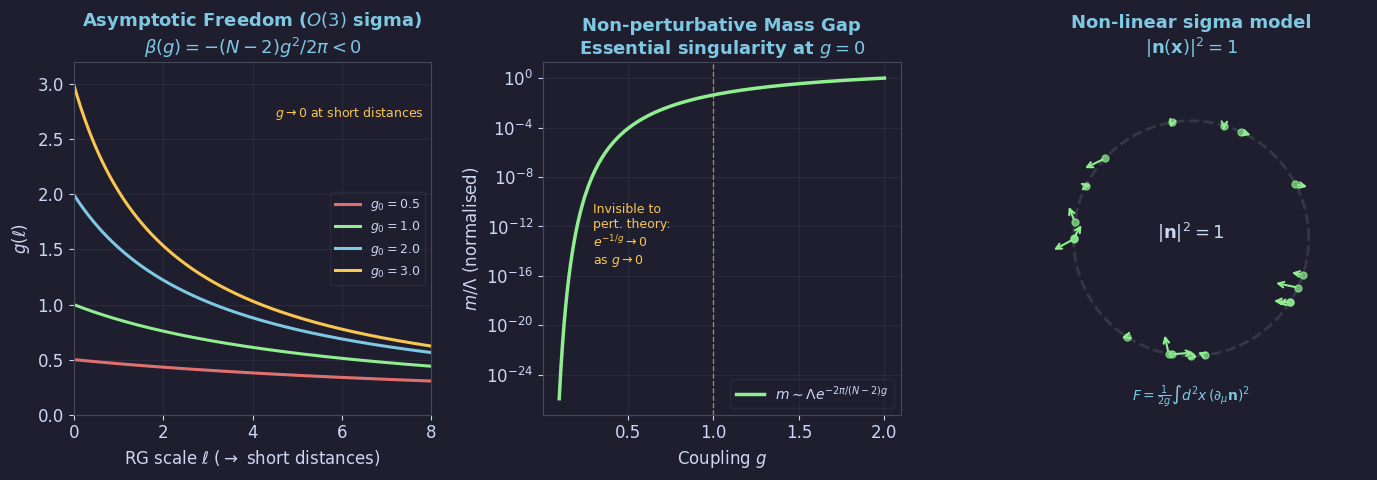

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03: Sigma model — asymptotic freedom, mass gap (Ch 4.3) ───────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Panel 1: running coupling (asymptotically free)
ax = axes[0]
ell = np.linspace(0, 8, 300)
N_s = 3
beta_c = (N_s-2)/(2*np.pi)
for g0, col, lab in [(0.5,RED,'$g_0=0.5$'),(1.0,GREEN,'$g_0=1.0$'),
                      (2.0,BLUE,'$g_0=2.0$'),(3.0,YELLOW,'$g_0=3.0$')]:
    g_l = 1/(1/g0 + beta_c*ell)
    ax.plot(ell, g_l, color=col, lw=2.2, label=lab)
ax.axhline(0, color=EDGE, lw=0.5)
ax.set_xlabel(r'RG scale $\ell$ ($\to$ short distances)')
ax.set_ylabel(r'$g(\ell)$')
ax.set_title(r'Asymptotic Freedom ($O(3)$ sigma)'+'\n'+
             r'$\beta(g)=-(N-2)g^2/2\pi<0$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(0,8); ax.set_ylim(0,3.2)
ax.text(4.5, 2.7, r'$g\to0$ at short distances', color=YELLOW, fontsize=9)

# Panel 2: non-perturbative mass gap
ax2 = axes[1]
g_arr = np.linspace(0.1, 2.0, 200)
m_gap = np.exp(-1/(beta_c*g_arr)); m_gap /= m_gap[-1]
ax2.semilogy(g_arr, m_gap, color=GREEN, lw=2.5,
             label=r'$m\sim\Lambda e^{-2\pi/(N-2)g}$')
ax2.axvline(1.0, color=YELLOW, lw=1.0, ls='--', alpha=0.6)
ax2.set_xlabel(r'Coupling $g$'); ax2.set_ylabel(r'$m/\Lambda$ (normalised)')
ax2.set_title(r'Non-perturbative Mass Gap'+'\nEssential singularity at $g=0$', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG); ax2.grid(True)
ax2.text(0.3, 1e-15,
         'Invisible to\npert. theory:\n'+r'$e^{-1/g}\to0$'+'\n' +r'as $g \to 0$',
         color=YELLOW, fontsize=9)

# Panel 3: field on sphere schematic
ax3 = axes[2]
ax3.set_xlim(-1.5,1.5); ax3.set_ylim(-1.5,1.5)
ax3.set_aspect('equal'); ax3.axis('off')
ax3.set_title(r'Non-linear sigma model'+'\n'+r'$|\mathbf{n}(\mathbf{x})|^2=1$',
              color=BLUE)
theta_s = np.linspace(0, 2*np.pi, 200)
ax3.plot(np.cos(theta_s), np.sin(theta_s), color=EDGE, lw=2.0, ls='--', alpha=0.6)
np.random.seed(7)
for _ in range(18):
    angle = np.random.uniform(0, 2*np.pi)
    x0, y0 = np.cos(angle), np.sin(angle)
    dx = np.random.uniform(-0.22, 0.22)
    dy = np.random.uniform(-0.22, 0.22)
    ax3.annotate('', xy=(x0+dx, y0+dy), xytext=(x0, y0),
                arrowprops=dict(arrowstyle='->', color=GREEN,
                                lw=1.5, mutation_scale=10))
    ax3.plot(x0, y0, 'o', color=GREEN, ms=5, alpha=0.7)
ax3.text(0, 0.05, r'$|\mathbf{n}|^2=1$',
         ha='center', va='center', fontsize=13, color=FG)
ax3.text(0, -1.38,
         r'$F=\frac{1}{2g}\int d^2x\,(\partial_\mu\mathbf{n})^2$',
         ha='center', fontsize=10, color=BLUE)

plt.tight_layout(pad=1.2)
save('fig03_sigma_model.png', fig)


---
## fig04 · KT Transition (§4.4)

**Left**: Vortex free energy $F_v=(\pi J-2T)\ln(L/a)$ — sign change at $T_{KT}$. **Centre**: Superfluid stiffness with universal jump. **Right**: $\eta(T)=T/2\pi J$ up to $\eta(T_{KT})=1/4$.

  saved -> figures/ch04/fig04_kt_transition.png


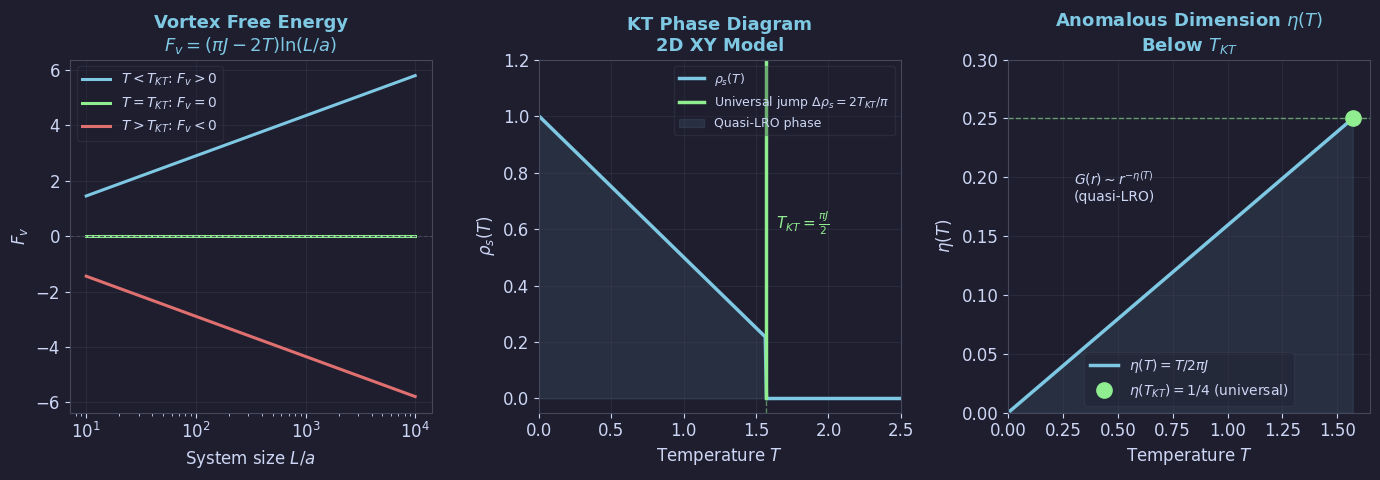

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04: KT transition — vortex free energy, phase diagram, eta (Ch 4.4) ─
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

J = 1.0; T_KT = np.pi*J/2
L_vals = np.logspace(1, 4, 200)
E_v = np.pi*J*np.log(L_vals)

ax = axes[0]
for T_val, col, lab in [(0.8*T_KT,BLUE,r'$T<T_{KT}$: $F_v>0$'),
                         (T_KT,GREEN,r'$T=T_{KT}$: $F_v=0$'),
                         (1.2*T_KT,RED,r'$T>T_{KT}$: $F_v<0$')]:
    ax.semilogx(L_vals, E_v-2*T_val*np.log(L_vals),
                color=col, lw=2.2, label=lab)
ax.axhline(0, color=EDGE, lw=0.8, ls='--')
ax.set_xlabel('System size $L/a$'); ax.set_ylabel('$F_v$')
ax.set_title(r'Vortex Free Energy'+'\n'+r'$F_v=(\pi J-2T)\ln(L/a)$', color=BLUE)
ax.legend(fontsize=10, labelcolor=FG); ax.grid(True)

ax2 = axes[1]
T_arr = np.linspace(0, 2.5, 300)
rho_s = np.maximum(J*(1-T_arr/(2*J)), 0)
rho_s[T_arr > T_KT] = 0
ax2.plot(T_arr, rho_s, color=BLUE, lw=2.5, label=r'$\rho_s(T)$')
ax2.plot([T_KT,T_KT],[0,np.pi*T_KT/2], color=GREEN, lw=2.5,
         label=r'Universal jump $\Delta\rho_s=2T_{KT}/\pi$')
ax2.axvline(T_KT, color=GREEN, lw=1.0, ls='--', alpha=0.5)
ax2.fill_between(T_arr[T_arr<T_KT], 0, rho_s[T_arr<T_KT],
                 color=BLUE, alpha=0.1, label='Quasi-LRO phase')
ax2.text(T_KT+0.07, 0.6, r'$T_{KT}=\frac{\pi J}{2}$',
         color=GREEN, fontsize=11)
ax2.set_xlabel('Temperature $T$'); ax2.set_ylabel(r'$\rho_s(T)$')
ax2.set_title('KT Phase Diagram\n2D XY Model', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0,2.5); ax2.set_ylim(-0.05,1.2)

ax3 = axes[2]
T_below = np.linspace(0.01, T_KT, 200)
eta_T = T_below/(2*np.pi*J)
ax3.plot(T_below, eta_T, color=BLUE, lw=2.5, label=r'$\eta(T)=T/2\pi J$')
ax3.plot([T_KT],[1/4],'o',color=GREEN,ms=11,zorder=5,
         label=r'$\eta(T_{KT})=1/4$ (universal)')
ax3.axhline(1/4, color=GREEN, lw=1.0, ls='--', alpha=0.6)
ax3.fill_between(T_below, 0, eta_T, color=BLUE, alpha=0.1)
ax3.text(0.3, 0.18, r'$G(r)\sim r^{-\eta(T)}$'+'\n(quasi-LRO)',
         color=FG, fontsize=10)
ax3.set_xlabel('Temperature $T$'); ax3.set_ylabel(r'$\eta(T)$')
ax3.set_title(r'Anomalous Dimension $\eta(T)$'+'\nBelow $T_{KT}$', color=BLUE)
ax3.legend(fontsize=10, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(0, T_KT*1.05); ax3.set_ylim(0, 0.30)

plt.tight_layout(pad=1.2)
save('fig04_kt_transition.png', fig)


---
## fig05 · KT RG Flow (§4.4.3)

**Left**: RG flow in $(K,y)$ space — fixed line at $y=0$, trajectories show vortex unbinding. **Right**: Correlation length $\xi\sim e^{b/\sqrt{t}}$ (essential singularity) vs power law.

  saved -> figures/ch04/fig05_kt_rg.png


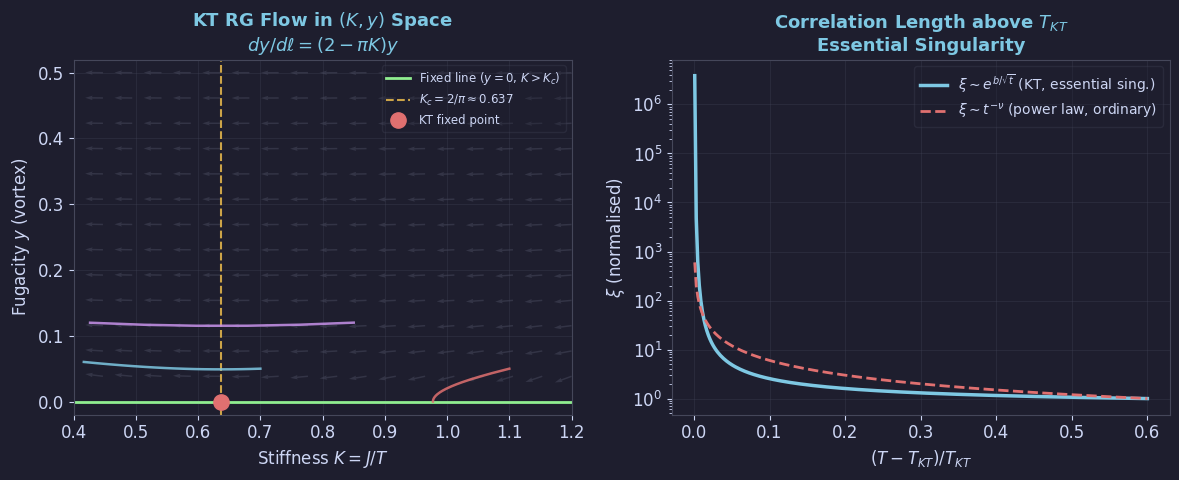

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig05: KT RG flow (K,y) + essential singularity (Ch 4.4) ─────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

K_vals = np.linspace(0.4, 1.2, 18)
y_vals = np.linspace(0.0, 0.5, 14)
K_g, Y_g = np.meshgrid(K_vals, y_vals)
dK = -4*np.pi**3*Y_g**2
dy = (2-np.pi*K_g)*Y_g
mag = np.sqrt(dK**2+dy**2)+1e-10

ax = axes[0]
ax.quiver(K_g, Y_g, dK/mag, dy/mag, color=EDGE, alpha=0.55, scale=28, width=0.003)
K_crit = 2/np.pi
ax.axhline(0, color=GREEN, lw=2.0, label=r'Fixed line ($y=0$, $K>K_c$)')
ax.axvline(K_crit, color=YELLOW, lw=1.5, ls='--', alpha=0.8,
           label=f'$K_c=2/\\pi\\approx{K_crit:.3f}$')
ax.plot([K_crit],[0],'o',color=RED,ms=11,zorder=5,label='KT fixed point')

def rg_kt(l, s):
    return [-4*np.pi**3*s[1]**2, (2-np.pi*s[0])*s[1]]

for K0, y0, col in [(0.7,0.05,BLUE),(0.85,0.12,PURPLE),
                     (0.55,0.20,ORANGE),(1.1,0.05,RED)]:
    sol = solve_ivp(rg_kt,[0,15],[K0,y0],max_step=0.1,dense_output=True)
    l_arr = np.linspace(0,15,300)
    traj = sol.sol(l_arr)
    mask = (traj[0]>0.4)&(traj[0]<1.2)&(traj[1]>=0)&(traj[1]<0.55)
    ax.plot(traj[0][mask], traj[1][mask], color=col, lw=1.8, alpha=0.85)

ax.set_xlabel(r'Stiffness $K=J/T$'); ax.set_ylabel('Fugacity $y$ (vortex)')
ax.set_title(r'KT RG Flow in $(K,y)$ Space'+'\n'+r'$dy/d\ell=(2-\pi K)y$',
             color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG)
ax.set_xlim(0.4,1.2); ax.set_ylim(-0.02,0.52); ax.grid(True)

J = 1.0; T_KT = np.pi*J/2
T_above = np.linspace(T_KT*1.001, T_KT*1.6, 300)
t_kt = (T_above-T_KT)/T_KT
xi_kt = np.exp(0.5/np.sqrt(t_kt)); xi_kt /= xi_kt[-1]
xi_pow = t_kt**(-1.0); xi_pow /= xi_pow[-1]

ax2 = axes[1]
ax2.semilogy(T_above/T_KT-1, xi_kt, color=BLUE, lw=2.5,
             label=r'$\xi\sim e^{b/\sqrt{t}}$ (KT, essential sing.)')
ax2.semilogy(T_above/T_KT-1, xi_pow, color=RED, lw=2.0, ls='--',
             label=r'$\xi\sim t^{-\nu}$ (power law, ordinary)')
ax2.set_xlabel(r'$(T-T_{KT})/T_{KT}$'); ax2.set_ylabel(r'$\xi$ (normalised)')
ax2.set_title(r'Correlation Length above $T_{KT}$'+'\nEssential Singularity', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG); ax2.grid(True)

plt.tight_layout(pad=1.2)
save('fig05_kt_rg.png', fig)


---
## Download All Figures

In [6]:
import os, zipfile
from google.colab import files

OUTDIR = 'figures/ch04'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')]) \
        if os.path.exists(OUTDIR) else []
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')

zip_name = 'sft_ch04_figures.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 5 figures:
  fig01_goldstone.png  (280 KB)
  fig02_mermin_wagner.png  (228 KB)
  fig03_sigma_model.png  (199 KB)
  fig04_kt_transition.png  (174 KB)
  fig05_kt_rg.png  (175 KB)
Zip: sft_ch04_figures.zip  (1002 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>